# CNW-Grass gas exchange, 1: your first run

**What you will learn:** compute the photosynthesis and the transpiration of a small wheat stand hour by hour over a
day, read the results (a table per hour, a table per leaf, a table per plant), and draw the stand coloured by its
photosynthesis.

**You need:** basic Python (running a cell, calling a function). No knowledge of photosynthesis models or of
metafspm is assumed. **Run time:** about 20 seconds.

This is the first of six user tutorials:

| | notebook | what you do |
|---|---|---|
| 1 | `01_first_run.ipynb` | a wheat stand's photosynthesis and transpiration over a day, read and plot the results |
| 2 | `02_change_a_parameter.ipynb` | find the parameters, change one: capacities, stomatal model, nitrogen, CO2, corrections |
| 3 | `03_combine_parameters.ipynb` | two capacities together: which one limits photosynthesis |
| 4 | `04_sensitivity_analysis.ipynb` | find which parameters matter most |
| 5 | `05_measured_weather.ipynb` | a measured weather, a clear and a cloudy day |
| 6 | `06_with_other_models.ipynb` | the light (Caribu), the plants (Adel) and a water model's leaf water potential |

Developers who want to understand how the component is written will find a second series in `../developer/`, best
read after this one.

## What the model computes

Leaves fix carbon from the air by **photosynthesis**: with the light they absorb, they turn CO₂ into sugars. To let
CO₂ in, they open small pores, the **stomata**; through the same pores they lose water vapour: this is
**transpiration**. Evaporating water cools the leaf, so its **temperature** differs from the air's.

CNW-Grass's gas exchange model computes, for every piece of leaf and stem (an **element**) and at every hour:

- its **gross assimilation** `Ag` and **net assimilation** `An` (the CO₂ fixed, minus the CO₂ respired in the light),
  in µmol of CO₂ per m² of the element per second;
- its **stomatal conductance** `gs` (how open its stomata are), in mol m⁻² s⁻¹;
- its **surface temperature** `Ts` (°C) and its **transpiration** `Tr` (mmol of water m⁻² s⁻¹).

These four depend on each other (photosynthesis opens the stomata, the stomata cool the leaf, the temperature changes
photosynthesis): the model solves them together, element by element. What it needs:

- the light each element absorbs (the **PAR**, *photosynthetically active radiation*, in µmol of photons m⁻² s⁻¹),
  computed here by the light model **Caribu**;
- each element's size, height and shape, from the wheat architecture model **Adel**;
- each element's **nitrogen** per unit area (g m⁻²): the more nitrogen, the more photosynthetic enzymes;
- the **weather**: the air temperature, humidity, CO₂ and wind.

Photosynthesis follows Farquhar's model: the leaf fixes CO₂ at the lower of two rates, the one its enzyme RuBisCO
allows and the one the light allows.

*References:* Farquhar G.D., von Caemmerer S., Berry J.A. (1980). A biochemical model of photosynthetic CO₂
assimilation in leaves of C3 species. *Planta* 149, 78–90. Barillot R., Chambon C., Andrieu B. (2016). CN-Wheat: a
functional–structural model of carbon and nitrogen metabolism in wheat culms after anthesis. I. Model description.
*Annals of Botany* 118, 997–1013.

*A word on metafspm:* the model is written with metafspm, a framework in which plant models are built as
**components** that can be combined (a light model, a plant architecture, a photosynthesis...). You do not need to
know it here; the last section says a word about how it works.

## 1. A day of gas exchange

`simulate` builds a small wheat stand and computes its gas exchange hour by hour over a day. With no argument:

- 12 wheat plants grown by Adel, in 3 rows 15 cm apart, 4 cm apart in a row, repeated on every side as in a field;
- grown to 600 °Cd (degree-days) since sowing, a few leaves each; each plant is a few degree-days older or younger
  than its neighbours, as in a real field;
- the day is 10 May at Paris, with the light of a clear day, the sun moving over the sky;
- a constant weather: 20 °C, 60 % relative humidity, 410 µmol mol⁻¹ of CO₂ (ppm), a wind of 2 m s⁻¹;
- every element has 2 g of nitrogen per m².

The hours are in universal time (UT).

In [1]:
import matplotlib.pyplot as plt

from openalea.cnwgrass.metafspm.simulation import simulate

result = simulate()

The **leaf area index** (LAI) describes how dense a canopy is: the green area of the plants (one face) per m² of
ground.

In [2]:
plants = result.plants()
print(f"{len(plants)} plants on {result.ground_area:.3f} m² of ground, "
      f"LAI = {plants['green_area'].sum() / result.ground_area:.2f}")

12 plants on 0.072 m² of ground, LAI = 0.62


## 2. The summary: one row per hour

`result.summary` is a table (a pandas DataFrame) with one row per hour. All the fluxes are **per m² of ground**:

| column | meaning | unit |
|---|---|---|
| `hour` | hour of the day (UT) | h |
| `PARi`, `air_temperature`, `relative_humidity`, `ambient_CO2`, `wind_speed` | the weather | |
| `PAR_absorbed` | PAR absorbed by the stand | µmol m⁻² s⁻¹ |
| `gross_assimilation`, `net_assimilation` | CO₂ fixed by the stand | µmol m⁻² s⁻¹ |
| `transpiration` | water lost by the stand | mmol m⁻² s⁻¹ |
| `surface_temperature` | mean temperature of the leaves and stems (weighted by their area) | °C |
| `stomatal_conductance` | mean stomatal conductance (weighted by area) | mol m⁻² s⁻¹ |

In [3]:
summary = result.summary
summary.round(2)

,hour,PARi,air_temperature,relative_humidity,ambient_CO2,wind_speed,PAR_absorbed,gross_assimilation,net_assimilation,transpiration,surface_temperature,stomatal_conductance
0,0.0,0.00,20.0,0.6,410.0,2.0,0.00,0.00,0.00,0.21,18.45,0.05
1,1.0,0.00,20.0,0.6,410.0,2.0,0.00,0.00,0.00,0.21,18.45,0.05
2,2.0,0.00,20.0,0.6,410.0,2.0,0.00,0.00,0.00,0.21,18.45,0.05
3,3.0,0.00,20.0,0.6,410.0,2.0,0.00,0.00,0.00,0.21,18.45,0.05
4,4.0,0.00,20.0,0.6,410.0,2.0,0.00,0.00,0.00,0.21,18.45,0.05
5,5.0,138.33,20.0,0.6,410.0,2.0,48.48,2.54,2.39,0.47,19.29,0.11
6,6.0,492.60,20.0,0.6,410.0,2.0,146.61,6.54,6.48,0.98,21.13,0.21
7,7.0,846.90,20.0,0.6,410.0,2.0,230.24,9.13,9.10,1.41,22.66,0.28
8,8.0,1177.08,20.0,0.6,410.0,2.0,300.96,10.72,10.68,1.79,23.87,0.32
9,9.0,1460.64,20.0,0.6,410.0,2.0,341.30,11.20,11.14,1.99,24.45,0.33


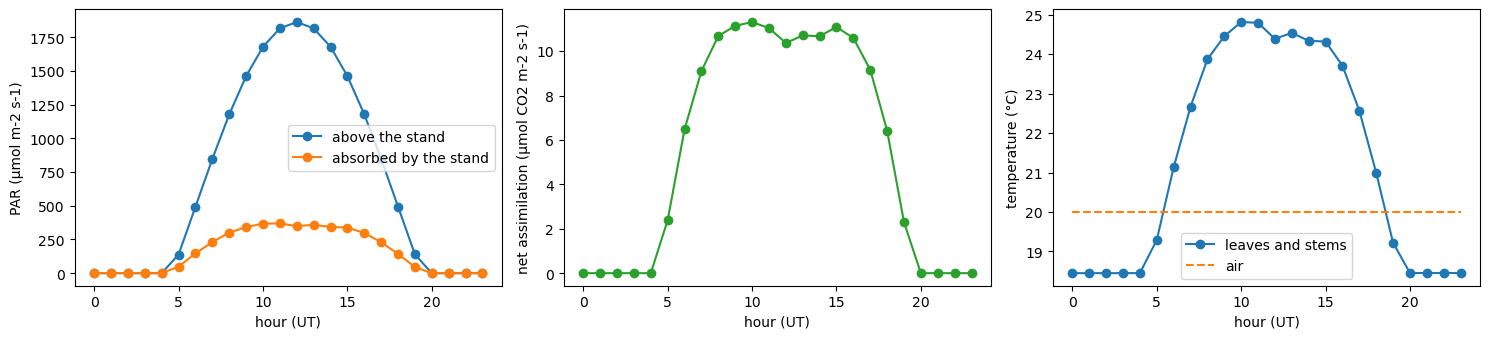

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
axes[0].plot(summary["hour"], summary["PARi"], "o-", label="above the stand")
axes[0].plot(summary["hour"], summary["PAR_absorbed"], "o-", label="absorbed by the stand")
axes[0].set_ylabel("PAR (µmol m-2 s-1)"); axes[0].legend()
axes[1].plot(summary["hour"], summary["net_assimilation"], "o-", color="tab:green")
axes[1].set_ylabel("net assimilation (µmol CO2 m-2 s-1)")
axes[2].plot(summary["hour"], summary["surface_temperature"], "o-", label="leaves and stems")
axes[2].plot(summary["hour"], summary["air_temperature"], "--", label="air")
axes[2].set_ylabel("temperature (°C)"); axes[2].legend()
for ax in axes:
    ax.set_xlabel("hour (UT)")
plt.tight_layout()

**Reading the curves.**

- The stand fixes CO₂ only in the light. Its net assimilation rises quickly in the morning, then stays nearly flat
  from 9 to 16 h while the light above the stand keeps changing: many leaves are **light-saturated**, their
  photosynthetic capacity is the limit. Around noon the absorbed PAR even dips a little: the high sun's light
  reaches the soil between the rows.
- At night it is 0: the model sets the assimilation to 0 when there is no light (the respiration in the dark is a
  respiration model's, not this model's).
- In the light the leaves are warmer than the air: they absorb radiation, and transpiration removes only part of it.
  At night they are cooler: they still transpire a little (the stomata never close completely), and evaporating
  water cools them.

The day's totals: the CO₂ fixed (44 g per mol) and the water lost (1 mmol of water is 18 mg; 1 kg per m² is 1 mm):

In [5]:
CO2 = summary["net_assimilation"].sum() * 3600 * 1e-6 * 44          # g of CO2 per m2 of ground
water = summary["transpiration"].sum() * 3600 * 18e-3 / 1000        # kg per m2 of ground, mm
print(f"over the day: {CO2:.1f} g CO2 m-2 fixed, {water:.2f} mm of water transpired, "
      f"{CO2 / water:.1f} g of CO2 per kg of water")

over the day: 21.1 g CO2 m-2 fixed, 1.65 mm of water transpired, 12.8 g of CO2 per kg of water


The last number is the stand's **water use efficiency**: the CO₂ it fixes per kg of water it loses.

## 3. Leaf by leaf, at noon

`result.elements()` lists every leaf and stem element with a green area, at the last hour computed. The day above
ended at 23 h, at night; one hour at noon:

In [6]:
noon = simulate(hours=1, start_hour=12)
elements = noon.elements()
elements.head()

,plant,organ,height,green_area,PARa,Ag,An,gs,Ci,Ts,Tr,transpiration
0,0,sheath,0.011142,0.000129,232.486617,9.015367,11.294359,0.221916,324.147630,21.751833,1.555281,0.000200
1,0,blade,0.022284,0.000057,1011.570570,29.417747,28.976934,0.495157,305.024539,30.187237,5.944286,0.000341
2,0,blade,0.022284,0.000213,618.538986,23.522060,23.177855,0.403927,309.117440,25.954722,3.698437,0.000787
3,1,sheath,0.011142,0.000129,107.323326,4.609589,5.673480,0.137427,341.725603,19.815713,0.890095,0.000114
4,1,blade,0.022284,0.000025,1607.694930,26.857142,26.211999,0.455309,307.628407,36.409836,9.416496,0.000235


Its columns: `plant`, `organ` (`blade`, `sheath` or `internode`), `height` (m), `green_area` (m²), `PARa` (the PAR it
absorbs, µmol m⁻² s⁻¹), `Ag`, `An`, `gs`, `Ci` (the CO₂ inside the leaf, µmol mol⁻¹), `Ts`, `Tr`, and `transpiration`
(Tr times its green area, mmol s⁻¹). A sheath's or a stem's `Ag` is 78 % of what a blade's would be (the parameter
`stem_efficiency`), its `An` not: the original model's choice, kept, which makes a sheath's `An` larger than its `Ag`.

Each element's net assimilation against the light it absorbs is a **light response curve**:

mean temperature of the elements absorbing more than 1300 µmol m-2 s-1: 33.9 °C, less than 500: 20.0 °C


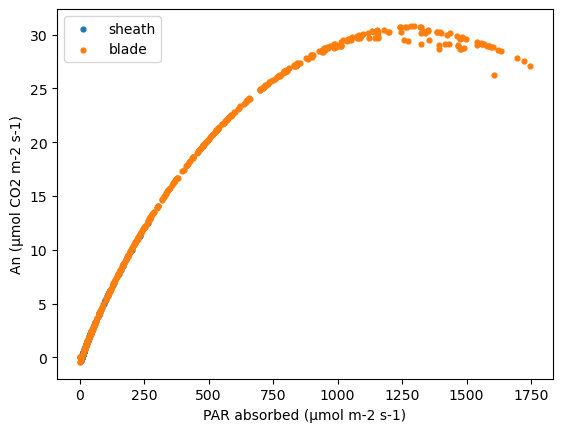

In [7]:
for organ in elements["organ"].unique():
    these = elements[elements["organ"] == organ]
    plt.scatter(these["PARa"], these["An"], s=12, label=organ)
plt.xlabel("PAR absorbed (µmol m-2 s-1)"); plt.ylabel("An (µmol CO2 m-2 s-1)"); plt.legend()
bright = elements["PARa"] > 1300
print(f"mean temperature of the elements absorbing more than 1300 µmol m-2 s-1: {elements['Ts'][bright].mean():.1f} °C, "
      f"less than 500: {elements['Ts'][elements['PARa'] < 500].mean():.1f} °C")

**Reading the figure.** Photosynthesis rises steeply at low light, then levels off: above about 1000 µmol m⁻² s⁻¹,
more light adds nothing. The most lit blades even fix a little less: they are also the warmest, and too warm a leaf
photosynthesises less. The sheaths, lower in the canopy, receive less light. Near 0, `An` is slightly negative: the
leaf respires more than it fixes.

## 4. Draw the stand

`noon.draw()` shows the stand in 3D, each element coloured by its net assimilation (`color_by=` another variable:
`"PARa"`, `"Ts"`, `"Tr"`...):

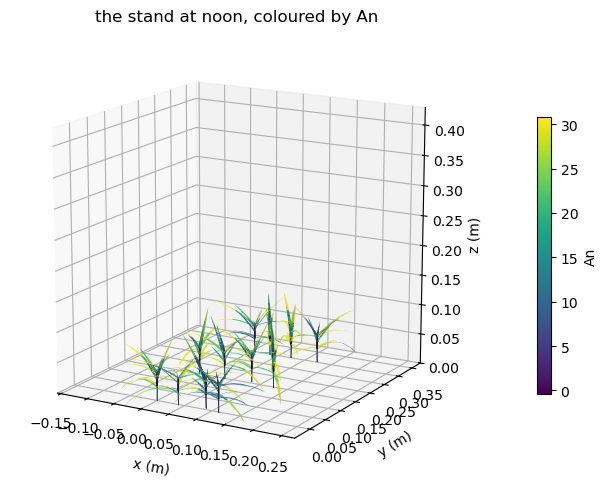

In [8]:
noon.draw()
plt.title("the stand at noon, coloured by An");

## 5. Per plant

`result.plants()` gives each plant's green area (m²), the CO₂ it fixed over the run (net, mmol) and the water it
transpired (g). The plants differ by their age and by their neighbours' shade:

In [9]:
plants = result.plants()
print(f"water transpired per plant over the day: from {plants['water'].min():.1f} to {plants['water'].max():.1f} g")
plants.round(4)

water transpired per plant over the day: from 8.9 to 10.8 g


,green_area,net_assimilation,water
plant,,,
0,0.0037,2.9086,10.0094
1,0.0038,2.7278,9.4380
2,0.0039,2.6764,8.9070
3,0.0039,2.9044,9.6659
4,0.0036,2.8076,9.8231
5,0.0036,2.8286,9.7564
6,0.0037,3.1212,10.8355
7,0.0037,2.8517,9.7175
8,0.0037,3.0655,10.5874


## Saving a run

With `outputs=`, `simulate` also writes the run in a folder: `run.json` (how the run went), `scenario.json` (what it
was made with, to run it again), `summary.csv` and `plants.csv` (the tables above, `plants.csv` hour by hour), and
`Plant/ExchangingWheat/summaries.csv` (every variable of every plant, every hour). Here in a temporary folder:

In [10]:
import json
import os
import tempfile

import pandas as pd

folder = tempfile.mkdtemp()
simulate(hours=1, start_hour=12, outputs=folder)
print(sorted(os.listdir(folder)))
with open(os.path.join(folder, "run.json")) as file:
    print(json.load(file)["status"])
pd.read_csv(os.path.join(folder, "summary.csv")).round(2)

['Plant', 'plants.csv', 'run.json', 'scenario.json', 'summary.csv']
finished


,hour,PARi,air_temperature,relative_humidity,ambient_CO2,wind_speed,PAR_absorbed,gross_assimilation,net_assimilation,transpiration,surface_temperature,stomatal_conductance
0,12.0,1861.94,20.0,0.6,410.0,2.0,342.88,10.17,10.03,2.0,24.47,0.31


## Try it yourself

1. Compute only the daylight hours: `simulate(hours=15, start_hour=5)`. Are the day's totals different?
2. Which element fixes the most CO₂ per m² at noon? How much light does it absorb, and how warm is it? (Use
   `elements` and `idxmax`.)
3. Draw the noon stand coloured by `"Ts"`. Which elements are the warmest?

**Next:** `02_change_a_parameter.ipynb`.

## Behind `simulate`: how the model is meant to be used

`simulate` is a convenience for these tutorials. The model is the component `GasExchange` (in
`openalea.cnwgrass.metafspm.gas_exchange`). In metafspm a component is not run on its own:

1. **The components.** `GasExchange` computes the gas exchange of the elements of a plant. It does not create plants
   nor compute the light: other components do.
2. **A plant model** (a metafspm `CompositeModel`) gathers the components of a plant and **couples** them, connecting
   what one computes to what another needs. `simulate`'s plant model, `ExchangingWheat` (in
   `openalea.cnwgrass.metafspm.simulation`), gathers Adel's architecture (the elements, their size and height),
   Caribu's optics (how much light each element reflects and transmits) and `GasExchange`.
3. **A scene** (a metafspm `Scene`) plants the plants and holds the **environment models**, which act on all the
   plants together: here Caribu's light. It runs them hour by hour and gives them the weather (metafspm's
   **forcings**). The light each element absorbs reaches `GasExchange` by its name, `PARa`.

The developer tutorials (`../developer/`) open these layers: the component's declarations and steps, the plant
model, the scene, and coupling the model with others (Caribu's light, MECHA's water flow).